# First results: routes 8, 65 and 66 across the Halsted and Chicago Avenue closures

TODO.md Phase 1, Now. Exploratory, no spec: three results from the Mansueto history (service dates 2022-06-01 to
2026-07-27), read in a way that no unfinished Phase 1 item can change.

1. Weekly travel time across the construction area, over the whole history.
2. The travel-time distribution by hour, before and during the closures.
3. Waits by hour at one reference stop per direction, as a rider who turns up at a random time experiences them.

Only stops that exist through the whole history are read: the segment brackets of
`notebooks/eda_routes_8_65_66.ipynb` section 6.6 and the reference stops of its section 8. That means one
source and nothing after 2026-07-27. Not for riders (ADR-002): it informs the Next specs.

**How the rows are read.** The plan was to read the run-level view under `data/route_run_level/`. Building it
needs one `getpatterns` call per pid, and on 2026-11-20 the Bus Tracker API answered every request with
"Invalid locale parameter", whatever the endpoint and whatever the key. So this notebook reads the Mansueto
parquets itself and passes them through `cta.mansueto.clean_trips`, with a pattern-stop table that holds only
the stops measured here. The read, DST, dedup and order stages run as they do for the view. The pattern join
keeps only those stops; today's patterns contain them and they exist through the whole history, so the view's
join would not drop them either. Section 1 checks this by reproducing the EDA's period medians to 0.1 minute.

In [1]:
%matplotlib inline

import json
import sys
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from cta import calendar as cta_calendar
from cta import mansueto
from cta.dlsd_run_quality import MIN_RUNS_RUSH_WEEKDAY_ELIGIBILITY

_style = REPO_ROOT / "notebooks" / "cta_analysis.mplstyle"
if _style.is_file():
    plt.style.use(_style)
plt.rcParams["figure.dpi"] = 72  # keeps the committed notebook small
pd.set_option("display.max_rows", 200, "display.max_columns", 40, "display.width", 200)

PARQUET_DIR = REPO_ROOT / "data" / "mansueto"  # trips_<pid>_full.parquet, as scripts/route_run_level.py caches them
PID_FILE = json.loads((REPO_ROOT / "notebooks" / "routes_8_65_66_pids.json").read_text())
TZ = mansueto.MANSUETO_TZ
ROUTES = ["8", "65", "66"]

MIN_RUNS_PER_CELL = MIN_RUNS_RUSH_WEEKDAY_ELIGIBILITY  # 30, the gate the EDA used (docs/2026-09-24-dlsd-rush-hour-min-sample.md)
DAYTIME_HOURS = (6, 20)  # runs entering 06:00 to 19:59 Chicago, as the EDA's medians
BEFORE = ("2024-09-03", "2025-08-03")  # both streets open, after Mansueto's stop-list switch (EDA 6.7)
DURING = ("2025-09-29", "2026-07-27")  # both closures in force, to the Mansueto edge
CLOSURES = {"2025-08-04": "Halsted closed", "2025-09-29": "Chicago Ave bridge closed"}  # news coverage, not yet confirmed (TODO.md Phase 1, Later)
WAIT_WINDOWS = {  # windows with no retired-pid rows (docs/2026-11-15-routes-8-65-66-run-level-qa.md)
    "8": ("2026-05-01", "2026-07-27"),
    "66": ("2026-05-01", "2026-07-27"),
    "65": ("2026-07-01", "2026-07-27"),  # 1.55% of rows missing in 2026-06, 5.08% to 7.50% before
}
WAIT_COMPARE = {  # same months a year apart, before and during the closure, each with few or no retired-pid rows (same note)
    "8": (("2025-05-01", "2025-07-27"), ("2026-05-01", "2026-07-27")),  # route 8: 0.16% to 0.44% missing in 2025
    "66": (("2025-07-01", "2025-07-27"), ("2026-07-01", "2026-07-27")),  # route 66: none missing from 2025-07
}
PLOT_HOURS = (5, 23)  # figures by hour start at 05:00: before it route 8 has no service and few runs make wild percentiles
COLOR_BEFORE, COLOR_DURING, INK = "#8f6edb", "#eb6834", "#333333"  # slots 1 and 2 of the style cycle (ADR-012)

# Segment brackets: notebooks/eda_routes_8_65_66.ipynb 6.6 output (both stops "throughout" the history).
SEGMENTS = pd.DataFrame(
    [
        ("8", "Northbound", "9376", "15356", "Halsted & Lake", "5950", "Halsted & North Ave"),
        ("8", "Southbound", "9368", "15407", "Halsted & North Ave", "15350", "Halsted & Lake"),
        ("65", "Eastbound", "6656", "729", "Grand & Ashland", "747", "Illinois & Clark"),
        ("65", "Westbound", "6657", "766", "Grand & Clark", "784", "Grand & Ashland"),
        ("66", "Eastbound", "6662", "556", "Chicago & Ashland", "18222", "Chicago & Clark"),
        ("66", "Westbound", "6665", "18487", "Chicago & Clark", "622", "Chicago & Ashland"),
    ],
    columns=["route", "direction", "pid", "from_stpid", "from_stop", "to_stpid", "to_stop"],
)
# Reference stops: the stop with the most arrivals per direction, 2026-05-01 to 2026-07-27 (EDA section 8 output).
REF_STOPS = pd.DataFrame(
    [
        ("8", "Northbound", "5931", "Halsted & Monroe"),
        ("8", "Southbound", "5815", "Halsted & 28th Street"),
        ("65", "Eastbound", "15516", "Fullerton & Grand"),
        ("65", "Westbound", "821", "Grand & Cicero"),
        ("66", "Eastbound", "523", "Chicago & Cicero"),
        ("66", "Westbound", "656", "Chicago & Lamon"),
    ],
    columns=["route", "direction", "stpid", "stop"],
)

PIDS = pd.DataFrame(PID_FILE["pids"]).astype({"pid": str, "route": str})
VIEW_PIDS = PIDS[PIDS["usable_mansueto"].fillna(False).astype(bool)]  # the 24 pids of the run-level view
DIRECTION = dict(zip(PIDS["pid"], PIDS["direction"]))
check = SEGMENTS.merge(PIDS[["pid", "route", "direction", "dominant"]], on="pid", suffixes=("", "_file"))
assert (check["route"] == check["route_file"]).all() and (check["direction"] == check["direction_file"]).all()
assert check["dominant"].fillna(False).all(), "a segment pid is not the dominant pattern of its direction"
missing = [p for p in VIEW_PIDS["pid"] if not mansueto.local_parquet_path(p, PARQUET_DIR).is_file()]
assert not missing, f"fetch these parquets first (mansueto.fetch_parquet): {missing}"
print(f"{len(VIEW_PIDS)} pids, {len(SEGMENTS)} segments, {len(REF_STOPS)} reference stops; parquets under {PARQUET_DIR}")

24 pids, 6 segments, 6 reference stops; parquets under /home/user/cta_bus_analysis/data/mansueto


## 1. Read and clean the rows at the measured stops

`read_stop_rows` projects the same seven columns as `cta.mansueto.read_trips`, adding a filter on `stpid` so
that the 15M-row files never reach pandas. Then it runs `clean_trips`. The QA table follows the adapter's
stages. `pattern_join` drops nothing here because only the measured stops are read, so it is a check that the
read filter worked.

In [2]:
_S = mansueto._str_sql  # the identifier normalisation read_trips uses ("6410.0" -> "6410")
con = duckdb.connect()


def read_stop_rows(pid: str, stpids: list[str]) -> tuple[pd.DataFrame, pd.DataFrame]:
    path = mansueto.local_parquet_path(pid, PARQUET_DIR)
    marks = ", ".join("?" for _ in stpids)
    trips = con.execute(
        f'''SELECT CAST(unique_trip_vehicle_day AS VARCHAR) run_id, {_S('rt')} route, {_S('pid')} pid,
                   {_S('vid')} vehicle_id, {_S('stpid')} stpid, CAST(stop_sequence AS BIGINT) stop_sequence, bus_stop_time
            FROM read_parquet(?) WHERE {_S('pid')} = ? AND {_S('stpid')} IN ({marks})''',
        [str(path), pid, *stpids],
    ).df()
    if trips["stop_sequence"].isna().any():
        trips["stop_sequence"] = trips["stop_sequence"].astype("Int64")
    stops = pd.DataFrame({"pid": pid, "stpid": list(stpids), "seq": range(len(stpids)), "rtdir": DIRECTION[pid]})
    clean, qa = mansueto.clean_trips(trips, stops)  # naive wall times in: the read stage localizes and counts DST drops
    return clean, qa.assign(pid=pid)


def add_day_type(df: pd.DataFrame) -> pd.DataFrame:
    dates = pd.Series(df["service_date"].unique())
    flag = cta_calendar.calendar_flag(dates)
    dow = pd.to_datetime(dates).dt.dayofweek
    kind = np.select([flag.str.contains("holiday"), dow <= 3, dow == 4], ["holiday", "Mon-Thu", "Fri"], "weekend")
    return df.assign(day_type=df["service_date"].map(dict(zip(dates, kind))))


qa_parts, tt_parts = [], []
for s in SEGMENTS.itertuples(index=False):
    clean, qa = read_stop_rows(s.pid, [s.from_stpid, s.to_stpid])
    qa_parts.append(qa.assign(purpose="segment", route=s.route, direction=s.direction))
    t = clean.set_index(["run_id", "service_date", "stpid"])["bus_stop_time"].unstack("stpid")
    both = t.dropna(subset=[s.from_stpid, s.to_stpid]).reset_index()
    tt_parts.append(pd.DataFrame({
        "route": s.route, "direction": s.direction, "pid": s.pid, "run_id": both["run_id"],
        "service_date": both["service_date"], "t_from": both[s.from_stpid],
        "minutes": (both[s.to_stpid] - both[s.from_stpid]).dt.total_seconds() / 60,
        "runs_read": len(t),
    }))
tt = pd.concat(tt_parts, ignore_index=True)
tt["hour"] = tt["t_from"].dt.tz_convert(TZ).dt.hour
tt = add_day_type(tt)
runs_read = tt.groupby(["route", "direction"])["runs_read"].first()
tt = tt.drop(columns="runs_read")
print(f"{len(tt):,} runs with both segment stops of {int(runs_read.sum()):,} runs at either; "
      f"segment time <= 0: {int((tt['minutes'] <= 0).sum()):,}; service dates {tt['service_date'].min()} to {tt['service_date'].max()}")

845,785 runs with both segment stops of 845,811 runs at either; segment time <= 0: 0; service dates 2022-06-01 to 2026-07-27


**Check: the EDA's period medians.** Mon to Thu, runs entering 06:00 to 19:59, median minutes from bracket to
bracket in the EDA's three periods (`docs/2026-11-13-routes-8-65-66-eda.md`, "Travel time across the area").
If the shortcut above changed any row that matters, this check fails.

In [3]:
EDA_PERIODS = [("2024-09-03", "2025-08-03"), ("2025-08-04", "2025-09-28"), ("2025-09-29", "2026-07-27")]
EDA_MEDIANS = {  # docs/2026-11-13-routes-8-65-66-eda.md
    ("8", "Southbound"): (12.8, 22.1, 20.7), ("8", "Northbound"): (13.2, 18.9, 18.4),
    ("66", "Eastbound"): (15.1, 15.3, 21.1), ("66", "Westbound"): (14.3, 14.2, 19.2),
    ("65", "Eastbound"): (13.5, 14.2, 15.0), ("65", "Westbound"): (12.6, 13.0, 13.6),
}
day = tt[(tt["day_type"] == "Mon-Thu") & tt["hour"].between(DAYTIME_HOURS[0], DAYTIME_HOURS[1] - 1) & (tt["minutes"] > 0)]
rows = []
for (route, direction), eda in EDA_MEDIANS.items():
    g = day[(day["route"] == route) & (day["direction"] == direction)]
    for (a, b), expected in zip(EDA_PERIODS, eda):
        rows.append({"route": route, "direction": direction, "period": f"{a} to {b}", "runs": int(g["service_date"].between(a, b).sum()),
                     "median_min": round(g.loc[g["service_date"].between(a, b), "minutes"].median(), 2), "eda_min": expected})
eda_check = pd.DataFrame(rows)
eda_check["diff"] = (eda_check["median_min"] - eda_check["eda_min"]).round(2)
display(eda_check)
assert eda_check["diff"].abs().max() <= 0.1, "the cleaned rows do not reproduce the EDA medians"

qa = pd.concat(qa_parts, ignore_index=True)
qa_summary = (qa.groupby(["purpose", "stage", "reason"], dropna=False)[["count"]].sum()
              .join(qa.drop_duplicates(["purpose", "pid", "stage"]).groupby(["purpose", "stage"])[["rows_in", "rows_out"]].sum(), on=["purpose", "stage"]))
display(qa_summary)

,route,direction,period,runs,median_min,eda_min,diff
0,8,Southbound,2024-09-03 to 2025-08-03,15276,12.76,12.8,-0.04
1,8,Southbound,2025-08-04 to 2025-09-28,2474,22.06,22.1,-0.04
2,8,Southbound,2025-09-29 to 2026-07-27,13758,20.73,20.7,0.03
3,8,Northbound,2024-09-03 to 2025-08-03,14582,13.17,13.2,-0.03
4,8,Northbound,2025-08-04 to 2025-09-28,2361,18.92,18.9,0.02
5,8,Northbound,2025-09-29 to 2026-07-27,13041,18.44,18.4,0.04
6,66,Eastbound,2024-09-03 to 2025-08-03,22649,15.13,15.1,0.03
7,66,Eastbound,2025-08-04 to 2025-09-28,4019,15.32,15.3,0.02
8,66,Eastbound,2025-09-29 to 2026-07-27,21936,21.14,21.1,0.04
9,66,Westbound,2024-09-03 to 2025-08-03,23114,14.30,14.3,0.00


count  rows_in  rows_out
purpose stage        reason                                      
segment dedup        nan                     0  1691596   1691596
        order        nan                     0  1691596   1691596
        pattern_join nan                     0  1691596   1691596
        read         dst_ambiguous_time     30  1691626   1691596
                     nan                     0  1691626   1691596

## 2. Travel time across the construction area, week by week

Weekly median and interquartile range of the bracket-to-bracket time, Mon to Thu, runs entering 06:00 to 19:59.
Weeks with fewer than 30 runs are not drawn. The blue band is the "before" period and the orange band is "during",
as used in section 3. Dotted lines mark the closure dates from news coverage, which are not yet confirmed. Minutes,
not minutes per mile: the distance between the brackets changed with each detour (`docs/2026-11-13-routes-8-65-66-eda.md`).

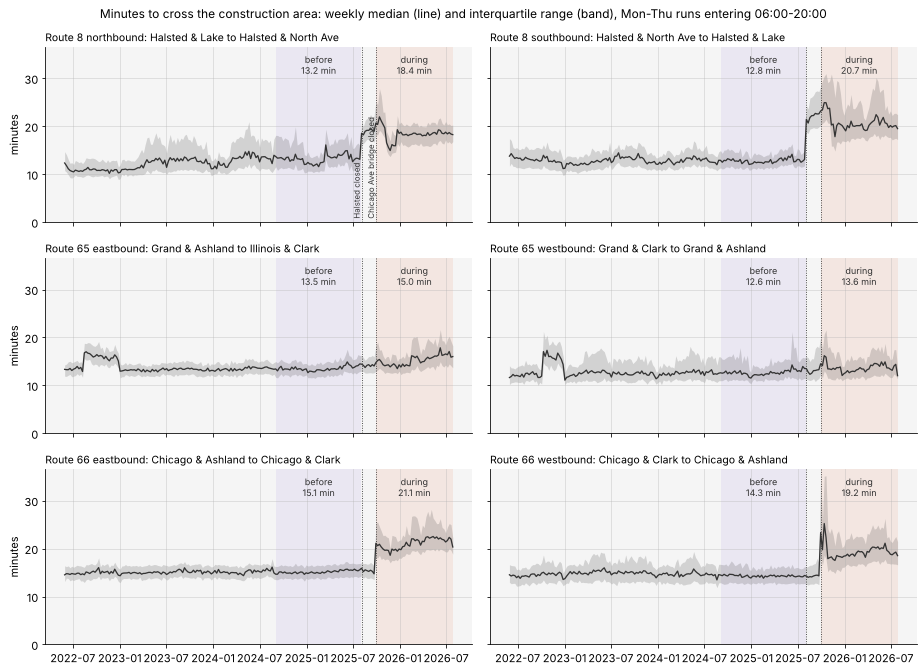

In [4]:
DIRS = {r: sorted(SEGMENTS.loc[SEGMENTS["route"] == r, "direction"]) for r in ROUTES}
day = day.assign(week=pd.to_datetime(day["service_date"]).dt.to_period("W-SUN").dt.start_time)
wq = (day.groupby(["route", "direction", "week"])["minutes"]
      .agg(n="size", q25=lambda s: s.quantile(0.25), median="median", q75=lambda s: s.quantile(0.75)).reset_index())
wq = wq[wq["n"] >= MIN_RUNS_PER_CELL]
period_median = {
    (r, d, name): day.loc[(day["route"] == r) & (day["direction"] == d) & day["service_date"].between(*span), "minutes"].median()
    for r in ROUTES for d in DIRS[r] for name, span in (("before", BEFORE), ("during", DURING))
}

fig, axes = plt.subplots(3, 2, figsize=(13, 9.5), sharex=True, sharey=True)
for i, route in enumerate(ROUTES):
    for j, direction in enumerate(DIRS[route]):
        ax = axes[i, j]
        seg = SEGMENTS[(SEGMENTS["route"] == route) & (SEGMENTS["direction"] == direction)].iloc[0]
        g = wq[(wq["route"] == route) & (wq["direction"] == direction)]
        for (a, b), color in ((BEFORE, COLOR_BEFORE), (DURING, COLOR_DURING)):
            ax.axvspan(pd.Timestamp(a), pd.Timestamp(b), color=color, alpha=0.10, lw=0)
        ax.fill_between(g["week"], g["q25"], g["q75"], color=INK, alpha=0.18, lw=0)
        ax.plot(g["week"], g["median"], color=INK, lw=1.3)
        for d in CLOSURES:
            ax.axvline(pd.Timestamp(d), color=INK, lw=0.9, ls=":")
        for name, (a, b) in (("before", BEFORE), ("during", DURING)):
            mid = pd.Timestamp(a) + (pd.Timestamp(b) - pd.Timestamp(a)) / 2
            ax.text(mid, 0.96, f"{name}\n{period_median[(route, direction, name)]:.1f} min", transform=ax.get_xaxis_transform(),
                    ha="center", va="top", fontsize=9, color=INK)
        ax.set_title(f"Route {route} {direction.lower()}: {seg['from_stop']} to {seg['to_stop']}", fontsize=10.5, loc="left")
        if j == 0:
            ax.set_ylabel("minutes")
for d, label in CLOSURES.items():
    axes[0, 0].annotate(label, (pd.Timestamp(d), 0.02), xycoords=("data", "axes fraction"), rotation=90,
                        ha="right", va="bottom", fontsize=8, color=INK)
axes[0, 0].set_ylim(bottom=0)
fig.suptitle("Minutes to cross the construction area: weekly median (line) and interquartile range (band), "
             f"Mon-Thu runs entering {DAYTIME_HOURS[0]:02d}:00-{DAYTIME_HOURS[1]:02d}:00", fontsize=12)
fig.tight_layout()
plt.show()

## 3. The travel-time distribution by hour, before and during

The same segments, Mon to Thu, by hour of entry. Before is 2024-09-03 to 2025-08-03; during is 2025-09-29 to
2026-07-27. The line is the median, the band the interquartile range, and the dashed line the 95th percentile,
the time a rider has to allow to arrive on time 19 times in 20. Hours with fewer than 30 runs in a period are not
drawn, nor are hours before 05:00. Route 8 has no service then, and the few owl runs give 95th percentiles over 100
minutes, which are runs that pause mid-route rather than crossings.

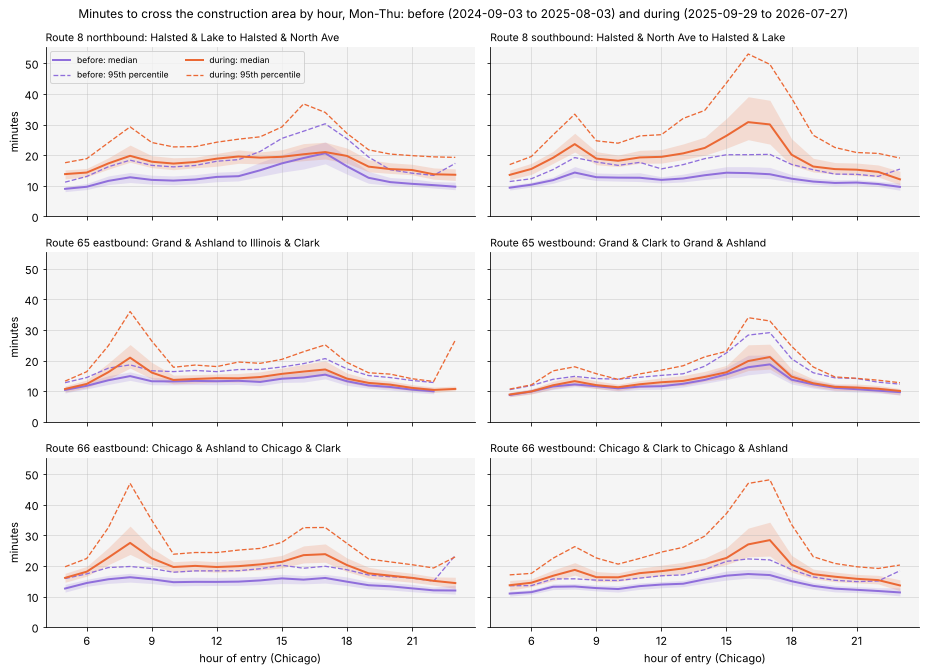

In [5]:
mt = tt[(tt["day_type"] == "Mon-Thu") & (tt["minutes"] > 0)].copy()
mt["period"] = np.select([mt["service_date"].between(*BEFORE), mt["service_date"].between(*DURING)], ["before", "during"], "")
mt = mt[mt["period"] != ""]
hq = (mt.groupby(["route", "direction", "period", "hour"])["minutes"]
      .agg(n="size", q25=lambda s: s.quantile(0.25), median="median", q75=lambda s: s.quantile(0.75), p95=lambda s: s.quantile(0.95))
      .reset_index())
hq = hq[hq["n"] >= MIN_RUNS_PER_CELL]

fig, axes = plt.subplots(3, 2, figsize=(13, 9.5), sharex=True, sharey=True)
for i, route in enumerate(ROUTES):
    for j, direction in enumerate(DIRS[route]):
        ax = axes[i, j]
        seg = SEGMENTS[(SEGMENTS["route"] == route) & (SEGMENTS["direction"] == direction)].iloc[0]
        for name, color in (("before", COLOR_BEFORE), ("during", COLOR_DURING)):
            g = hq[(hq["route"] == route) & (hq["direction"] == direction) & (hq["period"] == name) & hq["hour"].between(*PLOT_HOURS)]
            ax.fill_between(g["hour"], g["q25"], g["q75"], color=color, alpha=0.18, lw=0)
            ax.plot(g["hour"], g["median"], color=color, lw=2, label=f"{name}: median")
            ax.plot(g["hour"], g["p95"], color=color, lw=1.3, ls="--", label=f"{name}: 95th percentile")
        ax.set_title(f"Route {route} {direction.lower()}: {seg['from_stop']} to {seg['to_stop']}", fontsize=10.5, loc="left")
        ax.set_xticks(range(6, 24, 3))
        if j == 0:
            ax.set_ylabel("minutes")
        if i == 2:
            ax.set_xlabel("hour of entry (Chicago)")
axes[0, 0].set_ylim(bottom=0)
axes[0, 0].legend(fontsize=8.5, loc="upper left", ncols=2)
fig.suptitle("Minutes to cross the construction area by hour, Mon-Thu: before (2024-09-03 to 2025-08-03) and during "
             "(2025-09-29 to 2026-07-27)", fontsize=12)
fig.tight_layout()
plt.show()

The same numbers as a table. "Daytime" pools the hours 06:00 to 19:59. "Peak hour" is the hour whose median is
highest during the closures. "Slower than before's p95" is the share of crossings during the closures that took
longer than the slowest 5% of crossings before them.

In [6]:
dt_ = mt[mt["hour"].between(DAYTIME_HOURS[0], DAYTIME_HOURS[1] - 1)]
rows = []
for route in ROUTES:
    for direction in DIRS[route]:
        g = dt_[(dt_["route"] == route) & (dt_["direction"] == direction)]
        b, d = g.loc[g["period"] == "before", "minutes"], g.loc[g["period"] == "during", "minutes"]
        h = hq[(hq["route"] == route) & (hq["direction"] == direction)]
        peak = int(h[h["period"] == "during"].sort_values("median").iloc[-1]["hour"])
        hb = h[(h["period"] == "before") & (h["hour"] == peak)].iloc[0]
        hd = h[(h["period"] == "during") & (h["hour"] == peak)].iloc[0]
        rows.append({
            "route": route, "direction": direction,
            "runs_before": len(b), "runs_during": len(d),
            "median_before": b.median(), "median_during": d.median(),
            "p95_before": b.quantile(0.95), "p95_during": d.quantile(0.95),
            "slower_than_before_p95_pct": 100 * (d > b.quantile(0.95)).mean(),
            "peak_hour": peak, "peak_median_before": hb["median"], "peak_median_during": hd["median"],
            "peak_p95_before": hb["p95"], "peak_p95_during": hd["p95"],
        })
tt_summary = pd.DataFrame(rows)
tt_summary["median_change"] = tt_summary["median_during"] - tt_summary["median_before"]
tt_summary["p95_change"] = tt_summary["p95_during"] - tt_summary["p95_before"]
tt_summary["buffer_before"] = tt_summary["p95_before"] - tt_summary["median_before"]
tt_summary["buffer_during"] = tt_summary["p95_during"] - tt_summary["median_during"]
display(tt_summary.round(1).set_index(["route", "direction"]))

runs_before  runs_during  median_before  median_during  p95_before  p95_during  slower_than_before_p95_pct  peak_hour  peak_median_before  peak_median_during  peak_p95_before  \
route direction                                                                                                                                                                                    
8     Northbound        14582        13041           13.2           18.4        23.4        26.3                        11.8         17                20.6                21.0             30.3   
      Southbound        15276        13758           12.8           20.7        18.4        39.3                        69.2         16                14.2                30.8             20.2   
65    Eastbound          9272         8204           13.5           15.0        17.9        24.3                        23.2          8                14.9                20.9             18.6   
      Westbound          8632         7970           12.6           13.6        21.8        25.2                         9.1         17                18.8                21.2             29.1   
66    Eastbound         22649        21936           15.1           21.1        19.1        32.4                        71.5          8                16.3                27.5             19.8   
      Westbound         23114        21111           14.3           19.2        19.4        35.2                        48.0         17                17.0                28.4             22.0   

                  peak_p95_during  median_change  p95_change  buffer_before  buffer_during  
route direction                                                                             
8     Northbound             34.0            5.3         2.9           10.2            7.8  
      Southbound             53.0            8.0        20.9            5.6           18.5  
65    Eastbound              36.0            1.5         6.4            4.4            9.4  
      Westbound              32.9            1.0         3.4            9.2           11.6  
66    Eastbound              47.0            6.0        13.3            4.0           11.3  
      Westbound              48.1            4.9        15.7            5.1           16.0

## 4. Waits by hour at one reference stop per direction

Every arrival at the reference stop, all patterns of the direction pooled, as a rider who will board any bus going
that way sees them. A headway is the gap between consecutive arrivals on the same service day, assigned to the hour
of its midpoint. A rider who turns up at a random moment is more likely to land in a long gap than a short one, so:

- mean wait = sum of h² / (2 × sum of h), not half the mean headway;
- the share of riders waiting longer than w minutes = sum of max(h − w, 0) / sum of h.

"Evenly spaced" is half the mean headway: the mean wait if the same buses came at equal intervals. The difference
between the two, the bunching penalty, is what irregular spacing costs the average rider.

Windows: routes 8 and 66 from 2026-05-01 to 2026-07-27; route 65 from 2026-07-01 to 2026-07-27 only, because
before July it is missing up to 7.5% of its rows under retired pids (`docs/2026-11-15-routes-8-65-66-run-level-qa.md`)
and a missing run makes a gap look longer. All of these dates are during the closures.

In [7]:
stop_rows = {}  # (route, direction) -> every arrival at the reference stop, whole history, all view pids of the direction
for s in REF_STOPS.itertuples(index=False):
    parts = []
    for pid in VIEW_PIDS.loc[(VIEW_PIDS["route"] == s.route) & (VIEW_PIDS["direction"] == s.direction), "pid"]:
        clean, qa = read_stop_rows(pid, [s.stpid])
        qa_parts.append(qa.assign(purpose="wait", route=s.route, direction=s.direction))
        parts.append(clean[["pid", "run_id", "service_date", "bus_stop_time"]])
    stop_rows[(s.route, s.direction)] = add_day_type(pd.concat(parts, ignore_index=True))


def headways(route: str, direction: str, window: tuple[str, str]) -> pd.DataFrame:
    a = stop_rows[(route, direction)]
    a = a[a["service_date"].between(*window)].sort_values(["service_date", "bus_stop_time"])
    prev = a.groupby("service_date")["bus_stop_time"].shift()
    out = a.assign(prev=prev).dropna(subset=["prev"])
    out = out.assign(route=route, direction=direction, headway=(out["bus_stop_time"] - out["prev"]).dt.total_seconds() / 60,
                     hour=(out["prev"] + (out["bus_stop_time"] - out["prev"]) / 2).dt.tz_convert(TZ).dt.hour)
    return out


GRID = np.arange(0, 300.05, 0.1)  # minutes; longer than any daytime headway


def rider_wait(h: pd.Series) -> pd.Series:
    h = h.to_numpy(float)
    total = h.sum()
    share_over = np.clip(h[None, :] - GRID[:, None], 0, None).sum(axis=1) / total  # P(wait > w) for w on GRID
    reached = share_over <= 0.10
    return pd.Series({
        "headways": len(h), "median_headway": np.median(h), "even_wait": h.mean() / 2,
        "mean_wait": (h ** 2).sum() / (2 * total), "p90_wait": GRID[np.argmax(reached)] if reached.any() else np.nan,
        "wait_over_10_pct": 100 * np.clip(h - 10, 0, None).sum() / total, "wait_over_15_pct": 100 * np.clip(h - 15, 0, None).sum() / total,
        "headway_under_1_pct": 100 * (h < 1).mean(), "headway_over_30_pct": 100 * (h > 30).mean(), "headway_over_60": int((h > 60).sum()),
    })


def wait_table(hw: pd.DataFrame, by: list[str]) -> pd.DataFrame:
    day = hw[(hw["day_type"] == "Mon-Thu") & hw["hour"].between(DAYTIME_HOURS[0], DAYTIME_HOURS[1] - 1)]
    out = day.groupby(by)["headway"].apply(rider_wait).unstack()
    out["bunching_penalty"] = out["mean_wait"] - out["even_wait"]
    out["bunching_penalty_pct"] = 100 * out["bunching_penalty"] / out["even_wait"]
    return out


hw = pd.concat([headways(r, d, WAIT_WINDOWS[r]) for r, d in zip(REF_STOPS["route"], REF_STOPS["direction"])], ignore_index=True)
days = hw.drop_duplicates(["route", "direction", "service_date"]).groupby(["route", "direction", "day_type"]).size().unstack("day_type")
print("service days per window and day type:\n" + days.fillna(0).astype(int).to_string())

mt_hw = hw[hw["day_type"] == "Mon-Thu"]
hourly_wait = mt_hw.groupby(["route", "direction", "hour"])["headway"].apply(rider_wait).unstack().reset_index()
hourly_wait = hourly_wait[hourly_wait["headways"] >= MIN_RUNS_PER_CELL]
wait_summary = wait_table(hw, ["route", "direction"]).join(REF_STOPS.set_index(["route", "direction"])["stop"])
print(f"\nMon-Thu, headways whose midpoint falls {DAYTIME_HOURS[0]:02d}:00-{DAYTIME_HOURS[1]:02d}:00, windows of WAIT_WINDOWS:")
display(wait_summary.round(1))

service days per window and day type:
day_type          Fri  Mon-Thu  holiday  weekend
route direction                                 
65    Eastbound     4       15        1        7
      Westbound     4       15        1        7
66    Eastbound    13       48        2       25
      Westbound    13       48        2       25
8     Northbound   13       48        2       25
      Southbound   13       48        2       25



Mon-Thu, headways whose midpoint falls 06:00-20:00, windows of WAIT_WINDOWS:


headways  median_headway  even_wait  mean_wait  p90_wait  wait_over_10_pct  wait_over_15_pct  headway_under_1_pct  headway_over_30_pct  headway_over_60  bunching_penalty  \
route direction                                                                                                                                                                               
65    Eastbound      706.0            15.7        8.9       12.7      27.9              47.2              28.6                  0.1                 11.8             13.0               3.7   
      Westbound      838.0            13.5        7.5       12.9      27.6              47.0              29.0                  5.7                  7.4              9.0               5.4   
66    Eastbound     6460.0             5.8        3.1        4.5       9.2               8.0               2.5                  7.0                  0.1              0.0               1.4   
      Westbound     6410.0             4.9        3.1        5.6      12.2              16.3               5.1                 16.2                  0.3              0.0               2.5   
8     Northbound    4685.0             7.8        4.3        5.9      12.3              16.8               5.1                  3.2                  0.4              0.0               1.6   
      Southbound    5138.0             6.9        3.9        6.1      13.1              19.3               6.3                 10.8                  0.2              0.0               2.2   

                  bunching_penalty_pct                   stop  
route direction                                                
65    Eastbound                   41.6      Fullerton & Grand  
      Westbound                   72.6         Grand & Cicero  
66    Eastbound                   43.6       Chicago & Cicero  
      Westbound                   78.2        Chicago & Lamon  
8     Northbound                  37.8       Halsted & Monroe  
      Southbound                  54.7  Halsted & 28th Street

**Route 65's long gaps recur at the same times.** Its mean wait is twice what even spacing would give, and the
cause is gaps of about an hour that start at nearly the same clock time on most weekdays. Below are the daytime
gaps over 45 minutes, by direction and starting time. Mansueto alone cannot say whether a scheduled trip never ran,
or ran under a pid with no Mansueto parquet (29292, an eastbound Grand & Nordica to Grand & Pulaski pattern, is
absent from `rt_to_pid.csv`; `docs/2026-11-15-routes-8-65-66-run-level-qa.md`). The archive can, from 2026-09-28.

In [8]:
long_gaps = mt_hw[(mt_hw["headway"] > 45) & mt_hw["hour"].between(DAYTIME_HOURS[0], DAYTIME_HOURS[1] - 1)].copy()
long_gaps["starts"] = long_gaps["prev"].dt.tz_convert(TZ).dt.floor("15min").dt.strftime("%H:%M")
recurring = (long_gaps.groupby(["route", "direction", "starts"])
             .agg(days=("service_date", "nunique"), median_gap_min=("headway", "median")).reset_index())
mt_days = days.get("Mon-Thu")
recurring["of_mon_thu_days"] = [int(mt_days[(r, d)]) for r, d in zip(recurring["route"], recurring["direction"])]
display(recurring[recurring["days"] >= 2].sort_values(["route", "direction", "days"], ascending=[True, True, False]).round(1))

,route,direction,starts,days,median_gap_min,of_mon_thu_days
1,65,Eastbound,14:45,11,63.5,15
7,65,Eastbound,18:45,4,47.6,15
0,65,Eastbound,14:15,2,89.3,15
4,65,Eastbound,17:15,2,53.6,15
6,65,Eastbound,18:30,2,65.2,15
9,65,Westbound,10:00,12,59.0,15
11,65,Westbound,11:00,12,54.3,15
8,65,Westbound,09:45,2,68.8,15
15,8,Northbound,18:45,2,53.1,48


**Waits a year earlier, same months.** The table above is entirely during the closures. For routes 8 and 66 the
same months a year earlier are clean too: route 8 from 2025-05-01 to 2025-07-27, before Halsted closed, with under
0.5% of rows missing; route 66 in July 2025, before the Chicago Avenue bridge closed, with none missing. Each is
compared with the same months of 2026 at the same stop. Route 65 has no clean year-earlier window.

In [9]:
cmp_parts = []
for route, (before, during) in WAIT_COMPARE.items():
    for direction in DIRS[route]:
        for name, window in (("before", before), ("during", during)):
            cmp_parts.append(headways(route, direction, window).assign(period=f"{name} {window[0][:7]} to {window[1][:7]}"))
wait_compare = wait_table(pd.concat(cmp_parts, ignore_index=True), ["route", "direction", "period"])
display(wait_compare[["headways", "median_headway", "even_wait", "mean_wait", "bunching_penalty_pct", "p90_wait",
                      "wait_over_15_pct", "headway_under_1_pct"]].round(1))

headways  median_headway  even_wait  mean_wait  bunching_penalty_pct  p90_wait  wait_over_15_pct  headway_under_1_pct
route direction  period                                                                                                                                          
66    Eastbound  before 2025-07 to 2025-07    2133.0             5.8        3.0        4.1                  37.4       8.2               1.0                  8.0
                 during 2026-07 to 2026-07    1976.0             6.0        3.2        4.4                  36.5       9.0               2.2                  4.3
      Westbound  before 2025-07 to 2025-07    2052.0             4.9        3.1        5.4                  77.2      11.7               4.3                 16.3
                 during 2026-07 to 2026-07    1976.0             5.4        3.2        5.4                  69.3      11.6               3.9                 15.6
8     Northbound before 2025-05 to 2025-07    4665.0             8.0        4.3        6.2                  43.6      13.0               6.0                  5.4
                 during 2026-05 to 2026-07    4685.0             7.8        4.3        5.9                  37.8      12.3               5.1                  3.2
      Southbound before 2025-05 to 2025-07    4899.0             7.2        4.1        6.6                  62.1      14.1               8.1                 11.8
                 during 2026-05 to 2026-07    5138.0             6.9        3.9        6.1                  54.7      13.1               6.3                 10.8

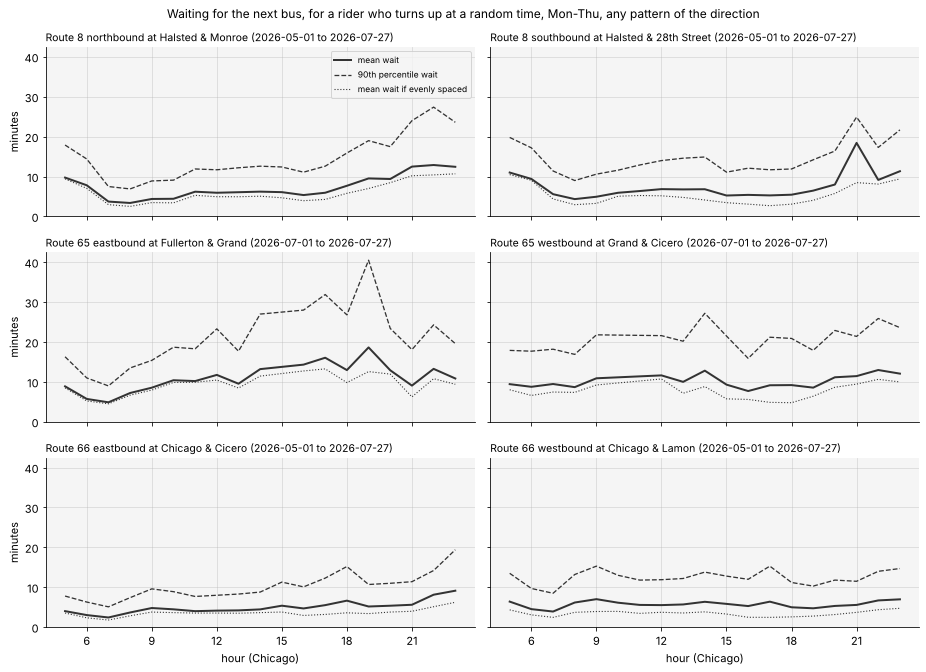

In [10]:
fig, axes = plt.subplots(3, 2, figsize=(13, 9.5), sharex=True, sharey=True)
for i, route in enumerate(ROUTES):
    for j, direction in enumerate(DIRS[route]):
        ax = axes[i, j]
        stop = REF_STOPS[(REF_STOPS["route"] == route) & (REF_STOPS["direction"] == direction)]["stop"].iloc[0]
        g = hourly_wait[(hourly_wait["route"] == route) & (hourly_wait["direction"] == direction) & hourly_wait["hour"].between(*PLOT_HOURS)]
        ax.plot(g["hour"], g["mean_wait"], color=INK, lw=2, label="mean wait")
        ax.plot(g["hour"], g["p90_wait"], color=INK, lw=1.3, ls="--", label="90th percentile wait")
        ax.plot(g["hour"], g["even_wait"], color=INK, lw=1.1, ls=":", label="mean wait if evenly spaced")
        a, b = WAIT_WINDOWS[route]
        ax.set_title(f"Route {route} {direction.lower()} at {stop} ({a} to {b})", fontsize=10.5, loc="left")
        ax.set_xticks(range(6, 24, 3))
        if j == 0:
            ax.set_ylabel("minutes")
        if i == 2:
            ax.set_xlabel("hour (Chicago)")
axes[0, 0].set_ylim(bottom=0)
axes[0, 0].legend(fontsize=8.5, loc="upper right")
fig.suptitle("Waiting for the next bus, for a rider who turns up at a random time, Mon-Thu, any pattern of the direction",
             fontsize=12)
fig.tight_layout()
plt.show()

## 5. Caveats

- **Mansueto imputes arrival times** linearly between pings about five minutes apart, and extrapolates them at
  trip ends (`docs/2026-09-23-mansueto-imputation-method.md`). A bracket-to-bracket time of 13 to 22 minutes
  spans several pings, so it is robust. A headway is less so: two buses a minute apart can be an imputation
  artefact, and the share of very short headways is an upper bound.
- **The run list is incomplete** where retired pids hold runs (route 65 until 2026-06, route 66 until 2025-06,
  route 8 under 0.5%). The wait windows avoid those months. Travel time is unaffected, because it reads one
  dominant pattern per direction.
- **Event days are not flagged** (TODO.md Phase 1, Later). The wait windows hold none of the days known so far;
  the weekly series may hold some.
- **Figures by hour start at 05:00.** Overnight, route 8 has no service, so the "headway" across the night is not
  a wait, and the few owl runs give percentiles from runs that pause mid-route. The daytime tables are unaffected.
- **Route 65's waits rest on one month** (July 2026) and are dominated by recurring hour-long gaps whose cause is
  open (section 4).
- **The closure dates** are from news coverage and from the EDA's daily medians, not yet from CDOT or CTA.
- **The rows were cleaned without `getpatterns`** (see the top). The check in section 1 reproduces the EDA's
  medians, and the QA table shows what each stage dropped.

## Findings

Measured 2026-11-20 from the Mansueto parquets (service dates 2022-06-01 to 2026-07-27). Rows were cleaned
through `cta.mansueto.clean_trips` at the measured stops only, because the Bus Tracker API was down (see the top).
The EDA's 18 period medians are reproduced to within 0.04 minute. Recorded in
`docs/2026-11-20-routes-8-65-66-first-results.md`.

1. **The closures added 5 to 8 minutes to a typical crossing, and much more to a bad one.** Mon to Thu, runs
   entering 06:00 to 19:59, minutes, before (2024-09-03 to 2025-08-03) → during (2025-09-29 to 2026-07-27):

   | Route, direction, segment | Median | 95th percentile | 95th minus median |
   |---|---|---|---|
   | 8 southbound, Halsted & North Ave to Lake | 12.8 → 20.7 | 18.4 → 39.3 | 5.6 → 18.5 |
   | 8 northbound, Halsted & Lake to North Ave | 13.2 → 18.4 | 23.4 → 26.3 | 10.2 → 7.8 |
   | 66 eastbound, Chicago & Ashland to Clark | 15.1 → 21.1 | 19.1 → 32.4 | 4.0 → 11.3 |
   | 66 westbound, Chicago & Clark to Ashland | 14.3 → 19.2 | 19.4 → 35.2 | 5.1 → 16.0 |
   | 65 eastbound, Grand & Ashland to Illinois & Clark | 13.5 → 15.0 | 17.9 → 24.3 | 4.4 → 9.4 |
   | 65 westbound, Grand & Clark to Ashland | 12.6 → 13.6 | 21.8 → 25.2 | 9.2 → 11.6 |

   During the closures, 69% of route 8 southbound crossings and 72% of route 66 eastbound crossings take longer
   than the slowest 5% did before; for route 66 westbound it is 48%.
2. **The peak hours carry most of it.** Route 8 southbound entering at 16:00: median 14.2 → 30.8 minutes, 95th
   percentile 20.2 → 53.0. Route 66 eastbound at 08:00: 16.3 → 27.5 and 19.8 → 47.0. Route 66 westbound at
   17:00: 17.0 → 28.4 and 22.0 → 48.1. Route 8 northbound is the exception: its PM peak was already slow
   (17:00 median 20.6 → 21.0), and the closure shows up midday instead (about 12 → 18 minutes from 09:00 to 13:00).
3. **Grand Avenue (route 65) slows in the morning.** Eastbound at 08:00 the median rose from 14.9 to 20.9
   minutes and the 95th percentile from 18.6 to 36.0, while the daytime median rose only 1.5 minutes. Whether
   this is traffic diverted from Chicago Avenue is not established.
4. **The step lands on the closure dates and has not eased.** Route 8 southbound weekly medians go from 12.5 to
   13.1 in July 2025 to 21.5 in the week of 2025-08-04, peak at 24.9 in mid-October 2025, and settle near 20 from
   mid-November 2025. Route 66 steps up in the week of 2025-09-29. Neither has moved back toward its before level
   by July 2026.
5. **Waits at the reference stops did not get worse.** The same months a year apart, Mon to Thu daytime, mean
   wait for a rider who turns up at a random time:
   - route 8 northbound at Halsted & Monroe, 6.2 → 5.9 minutes; southbound at Halsted & 28th Street, 6.6 → 6.1
     (May to July 2025 against 2026);
   - route 66 eastbound at Chicago & Cicero, 4.1 → 4.4; westbound at Chicago & Lamon, 5.4 → 5.4 (July against
     July).

   All four stops are outside the construction area; the closest is Halsted & Monroe, south of Lake Street.
   Waits next to the closed blocks are not measured here.
6. **Bunching costs riders 38% to 78% on top of even spacing.** From May to July 2026, the mean wait on routes 8
   and 66 is 4.5 to 6.1 minutes, where the same buses evenly spaced would give 3.1 to 4.3. Route 66 westbound at
   Chicago & Lamon is the worst: 5.6 minutes against 3.1, with 16% of headways under a minute (an upper bound,
   because arrival times are imputed).
7. **Route 65 has recurring hour-long gaps.** In July 2026 the mean wait is 12.7 minutes eastbound and 12.9
   westbound, and 29% of riders wait more than 15 minutes. Eastbound at Fullerton & Grand, a gap of about 64
   minutes starts near 14:45 on 11 of 15 Mon to Thu days. Westbound at Grand & Cicero, gaps of 54 to 59 minutes
   start near 10:00 and 11:00 on 12 of 15. Either those trips did not run, or they ran under a pid with no
   Mansueto parquet (29292). The archive can settle this from 2026-09-28.
8. **Route 65 had an unexplained slow period in 2022.** Weekly medians were 15.6 to 17.3 minutes from 2022-08-15
   to 2022-12-19 eastbound and from 2022-10-10 to 2022-12-12 westbound, against about 13 before and after. The
   cause is not established.
9. **For the Next specs:**
   - The view must reproduce the period medians above once `getpatterns` answers again.
   - The wait-time spec should report the random-arrival wait (sum of h² over 2 × sum of h), not half the
     headway: the difference between them is the bunching result.
   - Route 65 waits should not be published before its gaps are explained.